# Gravitational wave detection


The videos below show different representations of the gravitational waves that we aim to detect. We will aim to pick out the "chirp" signal of two colliding black holes from a very noisy backgound.

## Useful references
* [Topology of time series](https://giotto-ai.github.io/gtda-docs/latest/notebooks/topology_time_series.html), in which the Takens embedding technique used here is explained in detail and illustrated via simple examples.
* [Detection of gravitational waves using topological data analysis and convolutional neural network: An improved approach](https://arxiv.org/abs/1910.08245) by Christopher Bresten and Jae-Hun Jung.

## Motivation
The videos below show different representations of the gravitational waves that we aim to detect. We will aim to pick out the "chirp" signal of two colliding black holes from a very noisy backgound.

## Generate the data

In the article, the autors create a synthetic training set as follows: 

* Generate gravitational wave signals that correspond to non-spinning binary black hole mergers
* Generate a noisy time series and embed a gravitational wave signal with probability 0.5 at a random time.

The result is a set of time series of the form

$$ s = g + \epsilon \frac{1}{R}\xi $$

where $g$ is a gravitational wave signal from the reference set, $\xi$ is Gaussian noise, $\epsilon=10^{-19}$ scales the noise amplitude to the signal, and $R \in (0.075, 0.65)$ is a parameter that controls the signal-to-noise-ratio (SNR).

## Constant signal-to-noise ratio

As a warmup, let's generate some noisy signals with a constant SNR of 17.98. As shown in Table 1 of the article, this corresponds to an $R$ value of 0.65. By picking the upper end of the interval, we place ourselves in a favorable scenario and, thus, can gain a sense for what the best possible performance is for our time series classifier. We pick a small number of samples to make the computations run fast, but in practice would scale this by 1-2 orders of magnitude as done in the original article.

In [1]:
import numpy as np
from pathlib import Path

RANDOM_STATE = 42


def make_gravitational_waves(
    path_to_data: Path,
    n_signals: int = 30,
    downsample_factor: int = 2,
    r_min: float = 0.075,
    r_max: float = 0.65,
    n_snr_values: int = 10,
    signal_probability: float = 0.5,
    random_state: int = RANDOM_STATE,
):
    """Generate noisy time series with a configurable class balance and SNR."""

    rng = np.random.default_rng(random_state)

    # Oculta la señal agregando ruido antes y después.
    def padrand(V, n, kr):
        cut = rng.integers(n)
        rand1 = rng.standard_normal(cut)
        rand2 = rng.standard_normal(n - cut)
        return np.concatenate((rand1 * kr, V, rand2 * kr))

    Rcoef = np.linspace(r_min, r_max, n_snr_values)
    Npad = 500

    # We keep the data location used in the classroom notebook.
    gw = np.load(r"C:\Users\Ariel\Documents\topologia\gravitational_wave_signals.npy")
    Norig = len(gw["data"][0])
    Ndat = len(gw["signal_present"])
    N = int(Norig / downsample_factor)

    ncoeff = [10 ** (-19) * (1 / Rcoef[j % n_snr_values]) for j in range(n_signals)]

    # Exact class proportions make the balance experiment easy to interpret.
    n_present = int(round(n_signals * signal_probability))
    labels = np.concatenate(
        (np.ones(n_present, dtype=int), np.zeros(n_signals - n_present, dtype=int))
    )
    rng.shuffle(labels)

    noisy_signals = []
    gw_signals = []

    for j in range(n_signals):
        signal = gw["data"][j % Ndat][range(0, Norig, downsample_factor)]
        noise = ncoeff[j] * rng.standard_normal(N)

        if labels[j] == 1:
            rawsig = padrand(signal + noise, Npad, ncoeff[j])
        else:
            rawsig = padrand(noise, Npad, ncoeff[j])

        noisy_signals.append(rawsig.copy())
        gw_signals.append(signal)

    return np.asarray(noisy_signals), np.asarray(gw_signals), labels


## Separate experiments: class balance and SNR

The two effects are kept separate:

1. **Class-balance experiment:** keep $R=0.65$ fixed and change only the fraction of time series containing a gravitational wave.
2. **SNR experiment:** keep a 50/50 class balance and change only $R$, which controls the noise coefficient $10^{-19}/R$.

These comparisons are illustrative and use the same synthetic-data mechanism as the classroom exercise.

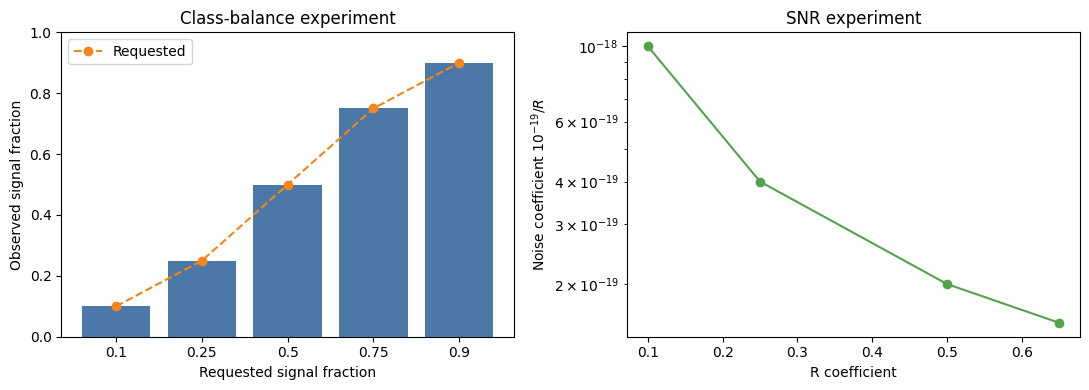

Number of noisy signals used below: 100
Number of timesteps per series: 8692
Signals present: 50 / 100


In [ ]:
import matplotlib.pyplot as plt

n_signals = 100
balance_rates = [0.10, 0.25, 0.50, 0.75, 0.90]
balance_observed = []

for case_index, positive_rate in enumerate(balance_rates):
    noisy_case, signal_case, labels_case = make_gravitational_waves(
        path_to_data=Path("."),
        n_signals=n_signals,
        r_min=0.65,
        r_max=0.65,
        n_snr_values=1,
        signal_probability=positive_rate,
        random_state=RANDOM_STATE + case_index,
    )
    balance_observed.append(labels_case.mean())

    # The 50/50 case is used in the rest of the notebook.
    if positive_rate == 0.50:
        noisy_signals = noisy_case
        gw_signals = signal_case
        labels = labels_case

snr_values = np.array([0.10, 0.25, 0.50, 0.65])
noise_coefficients = 10 ** (-19) / snr_values

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar([str(rate) for rate in balance_rates], balance_observed, color="#4C78A8")
axes[0].plot([str(rate) for rate in balance_rates], balance_rates, "o--", color="#F58518", label="Requested")
axes[0].set_title("Class-balance experiment")
axes[0].set_xlabel("Requested signal fraction")
axes[0].set_ylabel("Observed signal fraction")
axes[0].set_ylim(0, 1)
axes[0].legend()

axes[1].plot(snr_values, noise_coefficients, "o-", color="#54A24B")
axes[1].set_title("SNR experiment")
axes[1].set_xlabel("R coefficient")
axes[1].set_ylabel(r"Noise coefficient $10^{-19}/R$")
axes[1].set_yscale("log")

plt.tight_layout()
plt.show()

print(f"Number of noisy signals used below: {len(noisy_signals)}")
print(f"Number of timesteps per series: {len(noisy_signals[0])}")
print(f"Signals present: {labels.sum()} / {len(labels)}")


The left plot confirms that class balance changes independently of the noise level. The right plot shows that larger values of $R$ produce a smaller noise coefficient, so the signal is easier to distinguish.

Next let's visualise the two different types of time series that we wish to classify: one that is pure noise vs. one that is composed of noise plus an embedded gravitational wave signal:

In [3]:
import numpy as np
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# get the index corresponding to the first pure noise time series
background_idx = np.argmin(labels)
# get the index corresponding to the first noise + gravitational wave time series
signal_idx = np.argmax(labels)

ts_noise = noisy_signals[background_idx]
ts_background = noisy_signals[signal_idx]
ts_signal = gw_signals[signal_idx]

fig = make_subplots(rows=1, cols=2)

fig.add_trace(
    go.Scatter(x=list(range(len(ts_noise))), y=ts_noise, mode="lines", name="noise"),
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=list(range(len(ts_background))),
        y=ts_background,
        mode="lines",
        name="background",
    ),
    row=1,
    col=2,
)

fig.add_trace(
    go.Scatter(x=list(range(len(ts_signal))), y=ts_signal, mode="lines", name="signal"),
    row=1,
    col=2,
)
fig.show()

We make two observations:
1. It is hard to distinguish the signal by eye,
2. The signal features some regularity or periodicity.

Both observations lead us to examining the _**Takens embedding**_ of the signal $s(t)$, in order to pick up the recurrent structure. Indeed, if $f$ is sampled from a dynamical system with a non-trivial recurrent structure, then, for appropriate parameters, the image by the embedding will have non-trivial topology.

More formally,, we extract a sequence of vectors in $\mathbb{R}^{d}$ of the form

$$
TD_{d,\tau} s : \mathbb{R} \to \mathbb{R}^{d}\,, \qquad t \to \begin{bmatrix}
           s(t) \\
           s(t + \tau) \\
           s(t + 2\tau) \\
           \vdots \\
           s(t + (d-1)\tau)
         \end{bmatrix},
$$
where $d$ is the embedding dimension and $\tau$ is the time delay. The quantity $(d-1)\tau$ is known as the "window size" and the difference between $t_{i+1}$ and $t_i$ is called the stride.

Let's examine what the time delay embedding of a pure gravitational wave signal looks like:

In [ ]:
from gtda.time_series import SingleTakensEmbedding

embedding_dimension = 30
embedding_time_delay = 30
stride = 5

embedder = SingleTakensEmbedding(
    parameters_type="search",
    n_jobs=6,
    time_delay=embedding_time_delay,
    dimension=embedding_dimension,
    stride=stride,
)

y_gw_embedded = embedder.fit_transform(gw_signals[0])
print("Time delay used:", embedder.time_delay_)
print("Embedding dimension used:", embedder.dimension_)


Time delay used: 29
Embedding dimension used: 20


We can use PCA to project our high-dimensional space to 3-dimensions for visualisation:

In [ ]:
from sklearn.decomposition import PCA
from gtda.plotting import plot_point_cloud

pca = PCA(n_components=3)
y_gw_embedded_pca = pca.fit_transform(y_gw_embedded)

plot_point_cloud(y_gw_embedded_pca)

From the plot we can see that the decaying periodic signal generated by a black hole merger emerges as a _spiral_ in the time delay embedding space! For contrast, let's compare this to one of the pure noise time series in our sample:

In [ ]:
embedding_dimension = 30
embedding_time_delay = 30
stride = 5

embedder = SingleTakensEmbedding(
    parameters_type="search", n_jobs=6, time_delay=embedding_time_delay, dimension=embedding_dimension, stride=stride
)

y_noise_embedded = embedder.fit_transform(noisy_signals[background_idx])

pca = PCA(n_components=3)
y_noise_embedded_pca = pca.fit_transform(y_noise_embedded)

plot_point_cloud(y_noise_embedded_pca)

### Persistence diagrams for the two examples

The spiral is kept as an illustrative picture of the time-delay embedding. We now complement it with persistence diagrams for the signal and the noise. A persistent $H_1$ point represents a loop that survives across a comparatively wide range of scales.

In [ ]:
from gtda.plotting import plot_diagram

from gtda.homology import VietorisRipsPersistence

visual_persistence = VietorisRipsPersistence(homology_dimensions=[0, 1], n_jobs=-1)

signal_diagram = visual_persistence.fit_transform(y_gw_embedded_pca[None, :, :])
noise_diagram = visual_persistence.fit_transform(y_noise_embedded_pca[None, :, :])

print("Persistence diagram: gravitational-wave signal")
plot_diagram(signal_diagram[0])


Persistence diagram: gravitational-wave signal


In [ ]:
print("Persistence diagram: pure noise")
plot_diagram(noise_diagram[0])


Persistence diagram: pure noise


Evidently, pure noise resembles a high-dimensional ball in the time delay embedding space. Let's see if we can use persistent homology to tease apart which time series contain a gravitational wave signal versus those that don't. To do so we will adapt the strategy from the original article:

1. Generate 200-dimensional time delay embeddings of each time series
2. Use PCA to reduce the time delay embeddings to 3-dimensions
3. Use the Vietoris-Rips construction to calculate persistence diagrams of $H_0$ and $H_1$ generators
4. Extract feature vectors using persistence entropy
5. Train a binary classifier on the topological features

### Define the topological feature generation pipeline

We can do steps 1 and 2 by using the following ``giotto-tda`` tools:

- The ``TakensEmbedding`` transformer – instead of ``SingleTakensEmbedding`` – which will transform each time series in ``noisy_signals`` separately and return a collection of point clouds;
- ``CollectionTransformer``, which is a convenience "meta-estimator" for applying the same PCA to each point cloud resulting from step 1.

Using the ``Pipeline`` class from ``giotto-tda``, we can chain all operations up to and including step 4 as follows:

In [9]:
from gtda.diagrams import (
    Amplitude,
    BettiCurve,
    NumberOfPoints,
    PersistenceEntropy,
    PersistenceLandscape,
    Scaler,
)
from gtda.homology import VietorisRipsPersistence
from gtda.metaestimators import CollectionTransformer
from gtda.pipeline import Pipeline
from gtda.time_series import TakensEmbedding

embedding_dimension = 200
embedding_time_delay = 10
stride = 10


def make_topology_transformer():
    embedder = TakensEmbedding(
        time_delay=embedding_time_delay,
        dimension=embedding_dimension,
        stride=stride,
    )
    batch_pca = CollectionTransformer(PCA(n_components=3), n_jobs=-1)
    persistence = VietorisRipsPersistence(homology_dimensions=[0, 1], n_jobs=-1)
    return Pipeline([
        ("embedder", embedder),
        ("pca", batch_pca),
        ("persistence", persistence),
    ])


In [ ]:
from sklearn.model_selection import train_test_split

# Split the original time series first. PCA still reduces every embedded cloud
# to three dimensions, as in the classroom pipeline.
X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    noisy_signals,
    labels,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=labels,
)

train_topology = make_topology_transformer()
valid_topology = make_topology_transformer()

diagrams_train = train_topology.fit_transform(X_train_raw)
diagrams_valid = valid_topology.fit_transform(X_valid_raw)

diagram_scaler = Scaler()
diagrams_train_scaled = diagram_scaler.fit_transform(diagrams_train)
diagrams_valid_scaled = diagram_scaler.transform(diagrams_valid)

print("Training diagrams:", diagrams_train_scaled.shape)
print("Validation diagrams:", diagrams_valid_scaled.shape)


Training diagrams: (80, 1027, 3)
Validation diagrams: (20, 1018, 3)


### Train and evaluate a model

For the final step, let's train a simple classifier on our topological features. As usual we create training and validation sets

and then fit and evaluate our model:

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def flatten_features(values):
    return values.reshape(values.shape[0], -1)


feature_extractors = {
    "Persistence entropy": PersistenceEntropy(normalize=True, nan_fill_value=-10),
    "Amplitude": Amplitude(metric="bottleneck", n_jobs=-1),
    "Number of points": NumberOfPoints(n_jobs=-1),
    "Betti curves": BettiCurve(n_bins=50, n_jobs=-1),
    "Persistence landscapes": PersistenceLandscape(n_layers=2, n_bins=50, n_jobs=-1),
}

feature_results = []
feature_models = {}

for feature_name, transformer in feature_extractors.items():
    train_features = flatten_features(transformer.fit_transform(diagrams_train_scaled))
    valid_features = flatten_features(transformer.transform(diagrams_valid_scaled))

    classifier = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    )
    classifier.fit(train_features, y_train)

    train_probabilities = classifier.predict_proba(train_features)[:, 1]
    valid_probabilities = classifier.predict_proba(valid_features)[:, 1]

    result = {
        "feature": feature_name,
        "n_features": train_features.shape[1],
        "train_accuracy": accuracy_score(y_train, classifier.predict(train_features)),
        "valid_accuracy": accuracy_score(y_valid, classifier.predict(valid_features)),
        "train_auc": roc_auc_score(y_train, train_probabilities),
        "valid_auc": roc_auc_score(y_valid, valid_probabilities),
    }
    feature_results.append(result)
    feature_models[feature_name] = classifier

print(f"{'Topological descriptor':<26} {'Features':>8} {'Valid acc.':>11} {'Valid AUC':>10}")
for result in feature_results:
    print(
        f"{result['feature']:<26} {result['n_features']:>8} "
        f"{result['valid_accuracy']:>11.3f} {result['valid_auc']:>10.3f}"
    )


Topological descriptor     Features  Valid acc.  Valid AUC
Persistence entropy               2       0.750      0.890
Amplitude                         2       0.700      0.790
Number of points                  2       0.500      0.490
Betti curves                    100       0.650      0.820
Persistence landscapes          200       0.750      0.830


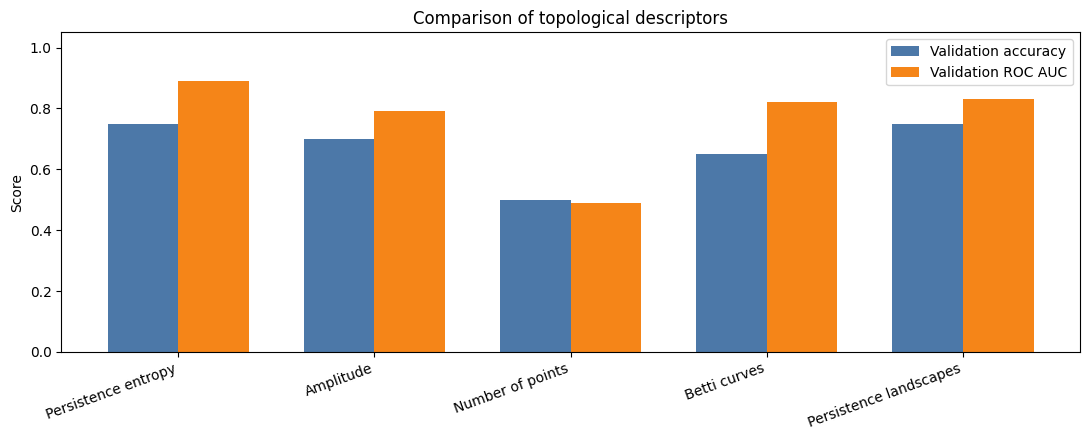

In [ ]:
feature_names = [result["feature"] for result in feature_results]
validation_accuracy = [result["valid_accuracy"] for result in feature_results]
validation_auc = [result["valid_auc"] for result in feature_results]

x = np.arange(len(feature_names))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - width / 2, validation_accuracy, width, label="Validation accuracy", color="#4C78A8")
ax.bar(x + width / 2, validation_auc, width, label="Validation ROC AUC", color="#F58518")
ax.set_xticks(x)
ax.set_xticklabels(feature_names, rotation=20, ha="right")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Comparison of topological descriptors")
ax.legend()
plt.tight_layout()
plt.show()


# Conclusion

The time-delay embedding gives an intuitive geometric view of the chirp: the gravitational-wave signal produces a spiral-like point cloud, while pure noise is more diffuse. Persistent homology summarizes how connected components and loops evolve across scale.

The final comparison keeps the same Takens embedding, three-dimensional PCA reduction and Vietoris--Rips construction used in class, but compares five summaries of the persistence diagrams: persistence entropy, amplitude, number of persistent points, Betti curves and persistence landscapes.

As a simple baseline, this model is not too bad - it outperforms the deep learning baseline in the article which typically fares little better than random on the raw data. However, the combination of deep learning and persistent homology is where significant performance gains are seen. Write code to perform this combination.